# OPTIMIZACIÓN DE HIPERPARÁMETROS PARA RANDOM FOREST

**Por**: Daniela Andrea Torres Gómez


**PARTE 3:** 
1. Explore la clasificación usando RandomForest sobre los datos Digits (sklearn.datasets.load_digits), que incluye 180 imágenes (8x8) de los dígitos del 0 al 10. Optimice los hiperparámetros empleando los métodos de búsqueda de grilla, búsqueda aleatoria y optimización bayesiana, presente tanto la precisión general de clasificación como la matriz de confusión.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn import datasets

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Metricas de desempeño
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#Importamos el modelo de bosques aleatorios para su entrenamiento
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from skopt import BayesSearchCV

## Clasificación

### Crear el dataframe de datos
**Digits**

In [4]:
digits_data = datasets.load_digits()
print(digits_data.feature_names)
print(digits_data.target_names)
print(digits_data.target)

['pixel_0_0', 'pixel_0_1', 'pixel_0_2', 'pixel_0_3', 'pixel_0_4', 'pixel_0_5', 'pixel_0_6', 'pixel_0_7', 'pixel_1_0', 'pixel_1_1', 'pixel_1_2', 'pixel_1_3', 'pixel_1_4', 'pixel_1_5', 'pixel_1_6', 'pixel_1_7', 'pixel_2_0', 'pixel_2_1', 'pixel_2_2', 'pixel_2_3', 'pixel_2_4', 'pixel_2_5', 'pixel_2_6', 'pixel_2_7', 'pixel_3_0', 'pixel_3_1', 'pixel_3_2', 'pixel_3_3', 'pixel_3_4', 'pixel_3_5', 'pixel_3_6', 'pixel_3_7', 'pixel_4_0', 'pixel_4_1', 'pixel_4_2', 'pixel_4_3', 'pixel_4_4', 'pixel_4_5', 'pixel_4_6', 'pixel_4_7', 'pixel_5_0', 'pixel_5_1', 'pixel_5_2', 'pixel_5_3', 'pixel_5_4', 'pixel_5_5', 'pixel_5_6', 'pixel_5_7', 'pixel_6_0', 'pixel_6_1', 'pixel_6_2', 'pixel_6_3', 'pixel_6_4', 'pixel_6_5', 'pixel_6_6', 'pixel_6_7', 'pixel_7_0', 'pixel_7_1', 'pixel_7_2', 'pixel_7_3', 'pixel_7_4', 'pixel_7_5', 'pixel_7_6', 'pixel_7_7']
[0 1 2 3 4 5 6 7 8 9]
[0 1 2 ... 8 9 8]


In [6]:

df = pd.DataFrame(digits_data.data)
df.columns = digits_data.feature_names
df['target'] = digits_data.target
df.head()

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7,target
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


In [7]:
df.describe()

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7,target
count,1797.0,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,...,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000
mean,0.0,0.303840,5.204786,11.835838,11.848080,5.781859,1.362270,0.129661,0.005565,1.993879,...,0.206455,0.000556,0.279354,5.557596,12.089037,11.809126,6.764051,2.067891,0.364496,4.490818
std,0.0,0.907192,4.754826,4.248842,4.287388,5.666418,3.325775,1.037383,0.094222,3.196160,...,0.984401,0.023590,0.934302,5.103019,4.374694,4.933947,5.900623,4.090548,1.860122,2.865304
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.000000,1.000000,10.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,11.000000,10.000000,0.000000,0.000000,0.000000,2.000000
50%,0.0,0.000000,4.000000,13.000000,13.000000,4.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,4.000000,13.000000,14.000000,6.000000,0.000000,0.000000,4.000000
75%,0.0,0.000000,9.000000,15.000000,15.000000,11.000000,0.000000,0.000000,0.000000,3.000000,...,0.000000,0.000000,0.000000,10.000000,16.000000,16.000000,12.000000,2.000000,0.000000,7.000000
max,0.0,8.000000,16.000000,16.000000,16.000000,16.000000,16.000000,15.000000,2.000000,16.000000,...,13.000000,1.000000,9.000000,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000,9.000000


### Separar en train and test

In [8]:
#Vamos a dividir los datos entre las muestras de entrenamiento y prueba

#Muestras
X1 = df.drop('target', axis=1)

#Etiquetas
y1 = df['target']

#Seleccionamos 70% de muestras para entrenamiento y 30% para prueba
X_train_digit, X_test_digit, y_train_digit, y_test_digit = train_test_split(X1, y1, test_size=0.3, random_state=42)

# normalizar los datos
scaler = MinMaxScaler()
X_train_digit = scaler.fit_transform(X_train_digit)
X_test_digit = scaler.transform(X_test_digit)
print("Tamaño de los datos de entrenamiento:", X_train_digit.shape, "Tamaño de los datos de prueba:", X_test_digit.shape)

Tamaño de los datos de entrenamiento: (1257, 64) Tamaño de los datos de prueba: (540, 64)


### Entrenamiento del modelo: Método de grilla

In [ ]:
#Creamos la grilla con los parametros a seleccionar
param_grid_1 = {
    'n_estimators': [10, 110, 10],
    'max_depth': [2, 3, 4, 5],
    'criterion': ['gini', 'entropy']
}


#Defimos el clasificador base
base_estimator_1 = RandomForestClassifier()

#Realizamos la busqueda de los hiperparametros
RF_estimator_1 = GridSearchCV(estimator=base_estimator_1, param_grid=param_grid_1)

# fit con la mejor combinacion de hiperparametros
RF_gridSearch_1 = RF_estimator_1.fit(X_train_digit, y_train_digit)

#Podemos ver que parametros fueron los seleccionados
RF_gridSearch_1.best_params_

{'criterion': 'entropy', 'max_depth': 5, 'n_estimators': 110}

              precision    recall  f1-score   support

           0       1.00      0.98      0.99        53
           1       0.96      0.94      0.95        50
           2       0.96      0.98      0.97        47
           3       0.93      0.93      0.93        54
           4       0.95      0.98      0.97        60
           5       0.97      0.95      0.96        66
           6       0.98      0.98      0.98        53
           7       0.92      0.98      0.95        55
           8       0.91      0.93      0.92        43
           9       0.94      0.86      0.90        59

    accuracy                           0.95       540
   macro avg       0.95      0.95      0.95       540
weighted avg       0.95      0.95      0.95       540



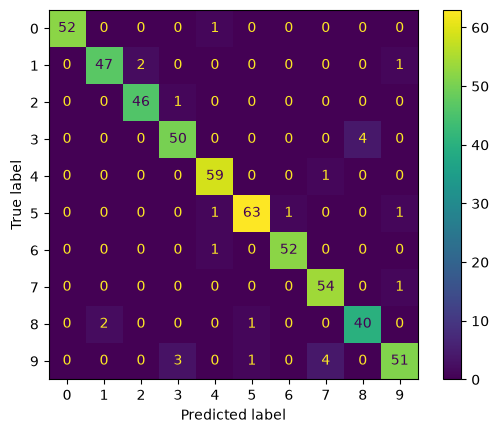

In [8]:
#Usamos el clasificador y analizamos su precision
y1_pred_digit = RF_gridSearch_1.best_estimator_.predict(X_test_digit)

#Matriz de confusion
cm_rf_1 = confusion_matrix(y_test_digit, y1_pred_digit)
print(metrics.classification_report(y_test_digit, y1_pred_digit))
ConfusionMatrixDisplay(confusion_matrix=cm_rf_1, display_labels=RF_gridSearch_1.best_estimator_.classes_).plot()


### Entrenamiento del modelo: Método de búsqueda aleatoria

In [ ]:
#Creamos la grilla de hiperparametros, entre las cuales se seleccionara de forma
#aleatoria la mejor configuracion
param_grid_2  = {
    'n_estimators': np.arange(10, 110, 10),
    'max_depth': np.arange(2, 6, 1),
    'criterion': ['gini', 'entropy']
}

#Definimos el clasificador base
base_estimator_2 = RandomForestClassifier()

#Seleccionamos los hiperparametros
random_search_2 = RandomizedSearchCV(estimator=base_estimator_2, param_distributions=param_grid_2, n_iter=10, cv=5,)

# fit con la mejor combinacion de hiperparametros
RF_randomSearch_2 = random_search_2.fit(X_train_digit, y_train_digit)

#Podemos ver que parametros fueron los seleccionados
RF_randomSearch_2.best_params_

{'n_estimators': np.int64(60),
 'max_depth': np.int64(5),
 'criterion': 'entropy'}

              precision    recall  f1-score   support

           0       0.98      0.98      0.98        53
           1       0.96      0.86      0.91        50
           2       0.92      0.98      0.95        47
           3       0.98      0.89      0.93        54
           4       0.95      0.98      0.97        60
           5       0.94      0.94      0.94        66
           6       0.98      0.98      0.98        53
           7       0.93      0.98      0.96        55
           8       0.89      0.93      0.91        43
           9       0.92      0.92      0.92        59

    accuracy                           0.94       540
   macro avg       0.94      0.94      0.94       540
weighted avg       0.95      0.94      0.94       540



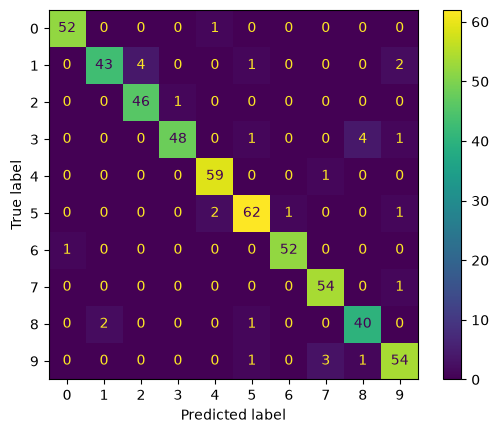

In [16]:
#Usamos el clasificador y analizamos su precision
y2_pred_digit = RF_randomSearch_2.best_estimator_.predict(X_test_digit)

#Matriz de confusion
cm_rf_2 = confusion_matrix(y_test_digit, y2_pred_digit)
print(metrics.classification_report(y_test_digit, y2_pred_digit))
ConfusionMatrixDisplay(confusion_matrix=cm_rf_2, display_labels=RF_randomSearch_2.best_estimator_.classes_).plot()

### Entrenamiento del modelo: Método Bayesiano

In [ ]:

#Creamos la grilla con los parametros a seleccionar
param_grid_3 = {'n_estimators':   np.arange(10,100,10),
                'criterion': ['gini','entropy'],
                'max_depth': [2,3,5,10]
}
#Defimos el clasificador base
base_estimator_3 = RandomForestClassifier(random_state=0)

#Realizamos la busqueda de los hiperparametros
opt_bayesian = BayesSearchCV(estimator=base_estimator_3, search_spaces=param_grid_3, n_iter=10, cv=5, random_state=0)

# fit con la mejor combinacion de hiperparametros
RF_opt_bayesian = opt_bayesian.fit(X_train_digit,y_train_digit)

#Podemos ver que parametros fueron los seleccionados
RF_opt_bayesian.best_params_

OrderedDict([('criterion', 'entropy'),
             ('max_depth', 10),
             ('n_estimators', 70)])

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        53
           1       0.93      1.00      0.96        50
           2       1.00      0.98      0.99        47
           3       1.00      0.93      0.96        54
           4       0.98      1.00      0.99        60
           5       0.96      0.97      0.96        66
           6       0.98      0.98      0.98        53
           7       0.98      0.98      0.98        55
           8       0.91      0.93      0.92        43
           9       0.98      0.95      0.97        59

    accuracy                           0.97       540
   macro avg       0.97      0.97      0.97       540
weighted avg       0.97      0.97      0.97       540



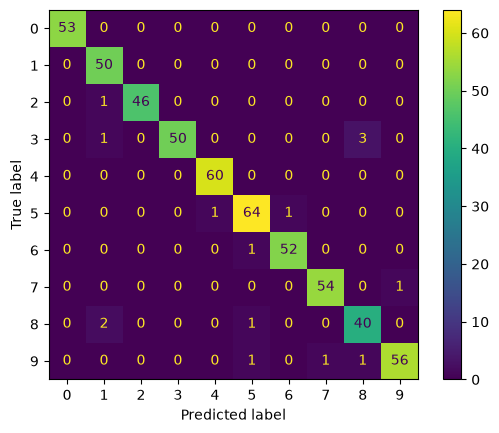

In [10]:
#Usamos el clasificador y analizamos su precision
y3_pred_digit = RF_opt_bayesian.best_estimator_.predict(X_test_digit)

#Matriz de confusion
cm_rf_3 = confusion_matrix(y_test_digit, y3_pred_digit)
print(metrics.classification_report(y_test_digit, y3_pred_digit))
ConfusionMatrixDisplay(confusion_matrix=cm_rf_3, display_labels=RF_opt_bayesian.best_estimator_.classes_).plot()

**Predicciones con una característica**

Con la mejor predicción

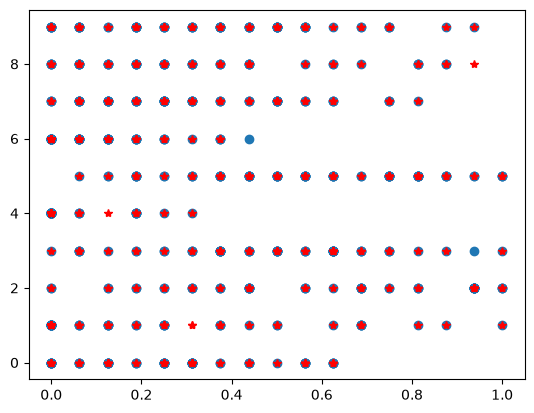

In [11]:
plt.plot(X_test_digit.T[2], y_test_digit,'o')
plt.plot(X_test_digit.T[2], y3_pred_digit,'*r')

### Predicción para un dato:

In [14]:
indice = 5
dato = pd.DataFrame(X_test_digit[indice].reshape(1, -1), columns=df.columns[:-1])
dato.head()


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_6,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
0,0.0,0.0,0.875,0.625,0.0,0.0,0.0,0.0,0.0,0.0,...,0.375,0.0,0.0,0.0,0.75,1.0,1.0,1.0,1.0,0.5625


In [15]:
prediccion = RF_opt_bayesian.best_estimator_.predict(X_test_digit[indice].reshape(1, -1))
print("Predicción para la muestra 1: ", prediccion[0], "Vs. Valor real: ", y_test_digit.iloc[indice])

Predicción para la muestra 1:  1 Vs. Valor real:  1


**Con el mejor estimador, ver la importancia de las características**

<Axes: >

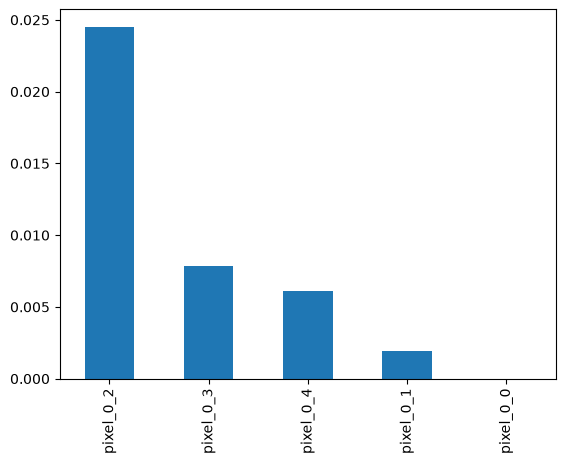

In [ ]:
# Serie con las caracteristicas mas importantes del modelo entrenado, junto con sus nombres
importances = pd.Series(RF_opt_bayesian.best_estimator_.feature_importances_[:5], index=df.columns[:5])
importances.sort_values(ascending=False).plot.bar()